# Single Agent vs Multi-Agent Systems with LangGraph + Ollama

Two **real-time, runnable** examples built with **LangGraph** and local **Ollama** models (free public APIs, no API keys):

| | Part 1: Single Agent | Part 2: Multi-Agent |
|---|---|---|
| Scenario | **Weather & Outfit Planner** | **Tech News Newsletter Team** |
| Real-time data | Open-Meteo weather API + system clock | Hacker News live API |
| Graph | `agent ⇄ tools` loop (ReAct) | `researcher → writer → editor` with a revise loop |
| LangGraph concepts | `StateGraph`, `ToolNode`, `tools_condition` | custom state, multiple nodes, conditional edges |

**Key idea:** an *agent* = LLM + instructions + tools + a loop. A *multi-agent system* = several specialised agents connected as nodes in a graph, passing shared state to each other.

## 0. Setup

In [ ]:
%pip install -q langgraph langchain-ollama langchain-core requests

Make sure Ollama is running and a **tool-capable** model is pulled:

```bash
ollama pull llama3.2
```
Other tool-capable options: `qwen2.5`, `llama3.1`, `mistral-nemo`. (`deepseek-r1` does not support tools.)

In [1]:
import datetime, requests
from typing import Annotated, TypedDict

from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.tools import tool
from langchain_ollama import ChatOllama
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

MODEL = "llama3.2"   # change to any tool-capable local model
llm = ChatOllama(model=MODEL, temperature=0)
print(llm.invoke("Say 'ready' in one word.").content)

Ready.


---
# Part 1 — Single Agent: Weather & Outfit Planner

**Scenario:** ask *"What should I wear in Bengaluru right now?"* One agent decides by itself which tools to call
(clock, live weather, today's forecast) and writes the answer.

**Why a single agent:** a small, linear chain of lookups with one coherent answer. More agents would only add overhead.

### Step 1 — Define tools

### 🤖 Agent profile — OutfitAgent (the single agent)
- **Goal:** answer "what should I wear / can I go out right now?" for any city using *real* conditions, not guesses.
- **Input:** a free-text question such as "What should I wear in Bengaluru right now?".
- **Tools:** `get_current_datetime` (clock), `get_weather` (live Open-Meteo weather), `get_today_forecast` (min/max temperature and rain chance).
- **Output:** a short 3-4 line recommendation: clothes, umbrella or not, and a tip for the time of day.
- **Why one agent is enough:** the whole job is a few lookups followed by one answer, so a single model deciding which tools to call is the simplest design.

In [2]:
@tool
def get_current_datetime() -> str:
    """Get the current local date, time and weekday."""
    return datetime.datetime.now().strftime("%A, %d %B %Y, %H:%M")

@tool
def get_weather(city: str) -> str:
    """Get live current weather for a city: temperature in C and F, feels-like, humidity, rain mm, wind km/h."""
    geo = requests.get("https://geocoding-api.open-meteo.com/v1/search",
                       params={"name": city, "count": 1}, timeout=10).json()
    if not geo.get("results"):
        return f"City '{city}' not found."
    p = geo["results"][0]
    w = requests.get("https://api.open-meteo.com/v1/forecast", params={
        "latitude": p["latitude"], "longitude": p["longitude"],
        "current": "temperature_2m,apparent_temperature,relative_humidity_2m,precipitation,wind_speed_10m",
    }, timeout=10).json()["current"]
    f_temp = w['temperature_2m'] * 9 / 5 + 32
    return (f"{p['name']}, {p.get('country','')}: {w['temperature_2m']}C / {f_temp:.1f}F (feels like {w['apparent_temperature']}C), "
            f"humidity {w['relative_humidity_2m']}%, rain {w['precipitation']} mm, wind {w['wind_speed_10m']} km/h")

@tool
def get_today_forecast(city: str) -> str:
    """Get today's forecast for a city: min/max temperature C and chance of rain %."""
    geo = requests.get("https://geocoding-api.open-meteo.com/v1/search",
                       params={"name": city, "count": 1}, timeout=10).json()
    if not geo.get("results"):
        return f"City '{city}' not found."
    p = geo["results"][0]
    d = requests.get("https://api.open-meteo.com/v1/forecast", params={
        "latitude": p["latitude"], "longitude": p["longitude"], "forecast_days": 1, "timezone": "auto",
        "daily": "temperature_2m_max,temperature_2m_min,precipitation_probability_max",
    }, timeout=10).json()["daily"]
    return (f"Today in {p['name']}: min {d['temperature_2m_min'][0]}C, max {d['temperature_2m_max'][0]}C, "
            f"chance of rain {d['precipitation_probability_max'][0]}%")

single_tools = [get_current_datetime, get_weather, get_today_forecast]
print(get_weather.invoke({"city": "Bengaluru"}))

Bengaluru, India: 27.5C / 81.5F (feels like 28.8C), humidity 36%, rain 0.0 mm, wind 7.5 km/h


### Step 2 — Build the graph

The classic ReAct loop: the **agent** node calls the LLM; if the LLM requests tools, `tools_condition` routes to the **tools** node, whose output flows back to the agent. When the LLM answers without tool calls, the graph ends.

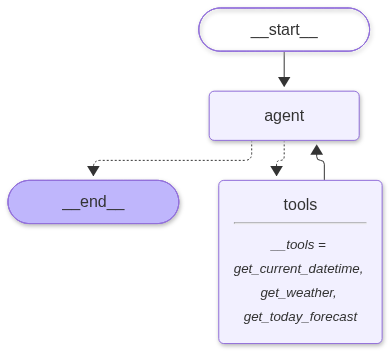

In [3]:
SINGLE_SYSTEM = (
    "You are a helpful outfit-planning assistant. ALWAYS use the tools to get the real date and live "
    "weather; never guess. Only call the tools the question needs. Then give a short recommendation (3-4 lines): what to wear, whether to "
    "carry an umbrella, and one tip for the time of day."
)
llm_with_tools = llm.bind_tools(single_tools)

class AgentState(TypedDict):
    messages: Annotated[list, add_messages]     # add_messages appends instead of overwriting

def agent_node(state: AgentState):
    return {"messages": [llm_with_tools.invoke([SystemMessage(SINGLE_SYSTEM)] + state["messages"])]}

builder = StateGraph(AgentState)
builder.add_node("agent", agent_node)
builder.add_node("tools", ToolNode(single_tools))
builder.add_edge(START, "agent")
builder.add_conditional_edges("agent", tools_condition)   # -> "tools" or END
builder.add_edge("tools", "agent")
single_agent = builder.compile()

single_agent   # renders the graph diagram in Jupyter

### Step 3 — Run it (streaming each step so you can watch the agent think)

In [4]:
def ask(question):
    print("USER:", question, "\n")
    final = None
    for update in single_agent.stream({"messages": [HumanMessage(question)]}, stream_mode="updates"):
        for node, out in update.items():
            msg = out["messages"][-1]
            if node == "agent" and msg.tool_calls:
                for tc in msg.tool_calls:
                    print(f"  [agent] calls tool {tc['name']}({tc['args']})")
            elif node == "tools":
                print(f"  [tools] {msg.content[:150]}")
            else:
                final = msg.content
    print("\nFINAL ANSWER:\n", final, "\n" + "-" * 60)

ask("What should I wear in Bengaluru right now? Also tell me the temperature in Fahrenheit and today's chance of rain.")

USER: What should I wear in Bengaluru right now? Also tell me the temperature in Fahrenheit and today's chance of rain. 

  [agent] calls tool get_weather({'city': 'Bengaluru'})
  [agent] calls tool get_today_forecast({'city': 'Bengaluru'})
  [agent] calls tool get_current_datetime({})
  [tools] Saturday, 14 November 2026, 11:51

FINAL ANSWER:
 Based on the current weather conditions in Bengaluru, I recommend wearing:

* Lightweight and breathable clothing such as cotton or linen shirts and pants
* Comfortable sandals or loafers for a casual look
* A light jacket or sweater for cooler evening hours

It's unlikely to rain today, so you can skip carrying an umbrella. However, it's always a good idea to pack one in case of unexpected showers.

Tip: Since the temperature is expected to be quite warm during the day, consider wearing clothing with built-in UPF protection to prevent sunburn. 
------------------------------------------------------------


In [ ]:
ask("Is it a good time for an evening run in London?")
ask("What day is it today?")      # should call only the clock tool

---
# Part 2 — Multi-Agent: Tech News Newsletter Team

**Scenario:** produce a short newsletter from *live* Hacker News stories. Three specialists collaborate:

```
 START → Researcher → Writer → Editor ──APPROVED──→ END
                        ▲         │
                        └─REVISE──┘   (max 2 revisions)
```

**Why multiple agents:** each role has a different prompt, goal and tools. Small focused prompts work much better on small local models, and the Editor gives an independent quality check the Writer can't give itself.

In LangGraph each agent is a **node**; they communicate through a shared **state**; the Editor's verdict drives a **conditional edge**.

### 🤖 Agent profiles — the Newsletter Team
**1. Researcher**
- **Goal:** find what is trending in tech *right now* and shortlist the 3 most interesting stories.
- **Input:** the live list of top Hacker News stories (title, score, comments, url).
- **Tools:** `fetch_hn_top_stories` (public Hacker News API).
- **Output:** a bullet list of 3 stories, each with its link and one line on why a tech audience would care.
- **Why it exists:** it is the only agent that touches live data, so the others never need to see raw API output.

**2. Writer**
- **Goal:** turn the researcher's notes into a friendly newsletter called "Tech Pulse".
- **Input:** the research notes, plus the Editor's feedback on later rounds.
- **Tools:** none; it only writes.
- **Output:** an intro line, one short paragraph per story with its link, and a sign-off.
- **Why it exists:** writing style and structure are a different skill from research, so it gets its own focused prompt.

**3. Editor**
- **Goal:** act as an independent quality gate on the Writer's draft.
- **Input:** the research notes and the current draft.
- **Tools:** none; it only reviews.
- **Output:** the word `APPROVED`, or `REVISE:` followed by 1-3 specific fixes (missing links, invented facts, tone).
- **Why it exists:** a writer cannot reliably check its own work; the Editor's verdict drives the loop back to the Writer (maximum 2 revisions).

In [ ]:
@tool
def fetch_hn_top_stories(count: int = 5) -> str:
    """Fetch the current top Hacker News stories (title, score, comments, url). count is 1-10."""
    count = max(1, min(int(count), 10))
    ids = requests.get("https://hacker-news.firebaseio.com/v0/topstories.json", timeout=10).json()[:count]
    lines = []
    for i in ids:
        s = requests.get(f"https://hacker-news.firebaseio.com/v0/item/{i}.json", timeout=10).json()
        lines.append(f"- {s.get('title')} | {s.get('score')} points | {s.get('descendants', 0)} comments | {s.get('url', 'no url')}")
    return "\n".join(lines)

print(fetch_hn_top_stories.invoke({"count": 3}))

### Shared state and agent prompts
Unlike Part 1 (just a message list), here the state holds named fields that each agent reads/writes.

In [ ]:
class TeamState(TypedDict):
    notes: str        # written by Researcher
    draft: str        # written by Writer
    feedback: str     # written by Editor ("APPROVED" or "REVISE: ...")
    revisions: int    # loop counter

RESEARCHER = ("You are a Research Analyst. Pick the 3 most interesting stories from the provided list. For each give: "
              "title, url, and ONE line on why a tech audience would care. Output only a bullet list.")
WRITER = ("You are a Newsletter Writer. Write a friendly newsletter titled 'Tech Pulse': a one-line intro, one short "
          "paragraph per story (include its link), and a one-line sign-off. Use ONLY facts from the notes. "
          "If editor feedback is given, revise the draft to address it.")
EDITOR = ("You are a strict Editor. Check the draft against the notes: (1) every story has a link, (2) no invented facts, "
          "(3) friendly and concise. Reply with exactly 'APPROVED' if good, otherwise 'REVISE:' plus 1-3 specific fixes.")

def chat(system, user):
    return llm.invoke([SystemMessage(system), HumanMessage(user)]).content

### Agent nodes
The **Researcher** is a tool-using agent: it fetches live data with its tool, then summarises. (To keep the example compact, the tool call is made by the node; swap in a full ReAct sub-graph from Part 1 if you want the LLM to choose.)

In [ ]:
def researcher_node(state: TeamState):
    print("== Researcher ==")
    raw = fetch_hn_top_stories.invoke({"count": 6})          # live data
    notes = chat(RESEARCHER, f"Today's top stories:\n{raw}")
    print(notes, "\n")
    return {"notes": notes, "revisions": 0}

def writer_node(state: TeamState):
    print(f"== Writer (revision {state['revisions']}) ==")
    prompt = f"Research notes:\n{state['notes']}"
    if state.get("draft"):
        prompt += f"\n\nPrevious draft:\n{state['draft']}\n\nEditor feedback:\n{state['feedback']}"
    draft = chat(WRITER, prompt)
    print(draft, "\n")
    return {"draft": draft}

def editor_node(state: TeamState):
    print("== Editor ==")
    verdict = chat(EDITOR, f"Research notes:\n{state['notes']}\n\nDraft:\n{state['draft']}")
    print(verdict, "\n")
    return {"feedback": verdict, "revisions": state["revisions"] + 1}

def route_after_editor(state: TeamState):
    if state["feedback"].strip().upper().startswith("APPROVED") or state["revisions"] > 2:
        return END
    return "writer"

### Wire the team together

In [ ]:
team = StateGraph(TeamState)
team.add_node("researcher", researcher_node)
team.add_node("writer", writer_node)
team.add_node("editor", editor_node)
team.add_edge(START, "researcher")
team.add_edge("researcher", "writer")
team.add_edge("writer", "editor")
team.add_conditional_edges("editor", route_after_editor, {"writer": "writer", END: END})
newsletter_team = team.compile()

newsletter_team   # renders the graph diagram

In [ ]:
result = newsletter_team.invoke({"notes": "", "draft": "", "feedback": "", "revisions": 0})
from IPython.display import Markdown
Markdown(result["draft"])

---
# Single vs Multi-Agent: when to use which

| | Single agent | Multi-agent |
|---|---|---|
| Best for | Simple, linear tasks with a few tools | Tasks with distinct roles / stages / review |
| Prompt size | Grows as you add duties | Small and focused per agent |
| Latency & cost | Lower (fewer LLM calls) | Higher (many calls) |
| Debugging | One trace | Need to trace handoffs (LangGraph streaming helps) |
| Quality control | Self-review only | Independent critic / verifier |
| LangGraph shape | `agent ⇄ tools` loop | Several nodes + conditional edges |

**Rule of thumb:** start with one agent; split only when one prompt becomes overloaded or you need independent checking.

### Ideas to extend
- Use a different model per node (e.g. a bigger model for the Editor): create a second `ChatOllama`.
- Add a *supervisor* node that routes between specialists dynamically.
- Add `MemorySaver` checkpointing to `compile(checkpointer=...)` for persistent conversations or human-in-the-loop approval before the newsletter is "published".